# Classification

Demo notebook shows examples of classification of Oder waters. The file is authored by Michał Jan Odorczuk and strongly (and shamelessly) bases on the code generated by ChatGPT.

Consult other notebooks for the full research process. The available notebooks are:
 - [Main notebook](main.ipynb) - notebook including the introduction of the problem and explanation of the available data and the area of interest.
 - [Data fetching notebook](data_fetching.ipynb) - notebook including the whole pipeline for fetching the data from the Copernicus database, filtering it, processing, and storing in the format used by the further analysis.
 - [Local maps notebook](local_maps.ipynb) - demo notebook showing examples of available data for the areas of interest in the form of maps of small regions within our area of interest.
 - [Profile notebook](profile.ipynb) - demo notebook showing examples of available data for the whole river in the form of spectral (and spectra-derived) characteristics along the Oder centreline.
 - [Classification notebook](classification.ipynb) - demo notebook showing examples of classification of Oder waters.

### Imports and setup

In [1]:
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path
from scripts.file_aux import stacks_to_dataframe, read_parameters
from scripts.plot_aux import normalise_rgb, add_grid_lines, plot_spectra_labels, mask_in_box
from matplotlib_map_utils import scale_bar
from matplotlib.colors import ListedColormap
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

SAVE_FIGS = True

In [2]:
parameters = read_parameters("metadata.json")
masked_dir = Path(parameters["data_directories"]["masked"])

band_names = parameters["bands"]["short_names"]["10m"] + parameters["bands"]["short_names"]["20m"]
band_names = [name for name in band_names if name != "SCL"]

bandwidths = parameters["bands"]["wavelength_bandwidths"]
band_wavelengths = parameters["bands"]["wavelengths"]
band_names = sorted(band_names, key=lambda band: band_wavelengths[band])
wavelengths = [band_wavelengths[band] for band in band_names]
bandwidths = [bandwidths[band] for band in band_names]

dates = os.listdir(masked_dir)
date_tiles = {date: {} for date in dates}
for date in dates:
    tiles = os.listdir(masked_dir / date)
    for tile in tiles:
        date_tiles[date][tile] = masked_dir / date / tile

In [3]:
def classify(df, labeled_masks, limit_mask, feature_columns=None, k=7):
    if feature_columns is None:
        feature_columns = band_names
    limit_mask = np.asarray(limit_mask, dtype=bool)

    labeled_masks = {label: np.asarray(mask, dtype=bool)[limit_mask] for label, mask in labeled_masks.items()}

    result_df = df.loc[limit_mask].copy()

    label_numbers = {label: number for number, label in enumerate(labeled_masks)}
    labels = np.full(len(result_df), -1, dtype=int)

    for label, mask in labeled_masks.items():
        labels[mask] = label_numbers[label]

    X = result_df[feature_columns].to_numpy(dtype=float)

    valid_features = np.isfinite(X).all(axis=1)
    training_mask = (labels >= 0) & valid_features

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=k,
            weights="distance",
            metric="minkowski",
            p=2,          # Euclidean distance
            n_jobs=-1
        )
    )

    model.fit(X[training_mask], labels[training_mask])

    result_df["predicted_class"] = None

    for label in label_numbers:
        result_df[f"prob_{label}"] = np.nan

    prediction_mask = valid_features
    predicted = model.predict(X[prediction_mask])
    probabilities = model.predict_proba(X[prediction_mask])

    number_labels = {number: label for label, number in label_numbers.items()}

    result_df.loc[prediction_mask, "predicted_class"] = [number_labels[number] for number in predicted]

    for probability_column, class_number in enumerate(model.classes_):
        label = number_labels[class_number]

        result_df.loc[
            prediction_mask,
            f"prob_{label}",
        ] = probabilities[:, probability_column]

    return result_df, model


In [4]:
aois = ["Oder_2", "Oder_3", "Oder_4"]
north, south, east, west = 52.7, 52.559, 14.67, 14.4
oder_lims = 52.58, 14.645, 52.56, 14.61
warta_lims = 52.63, 14.665, 52.582, 14.625
mixed_lims = 52.8, 14.35, 52.75, 14.3 # N, E, S, W
k_neighbours = 20

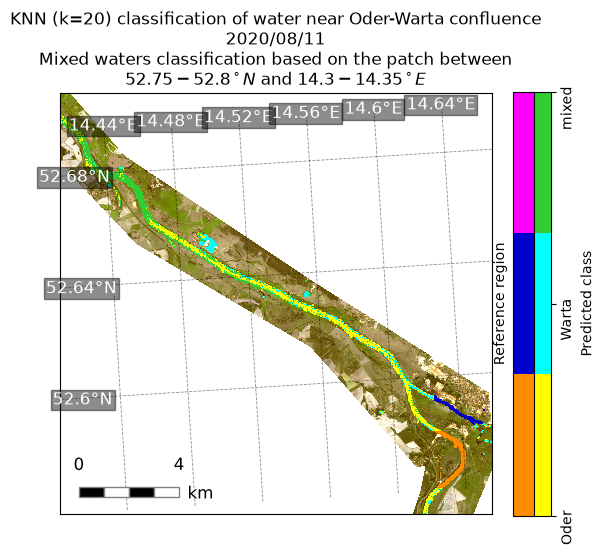

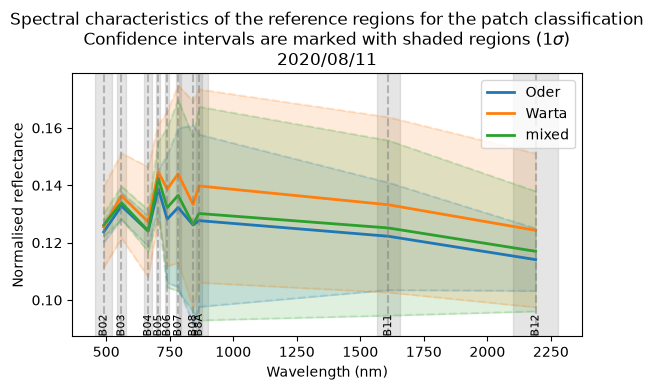

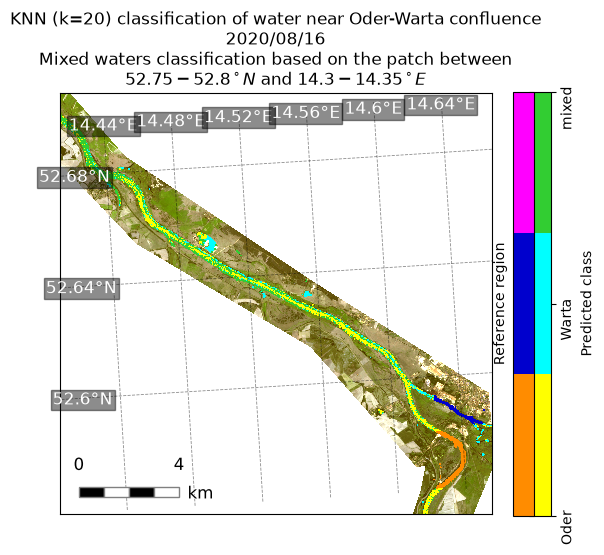

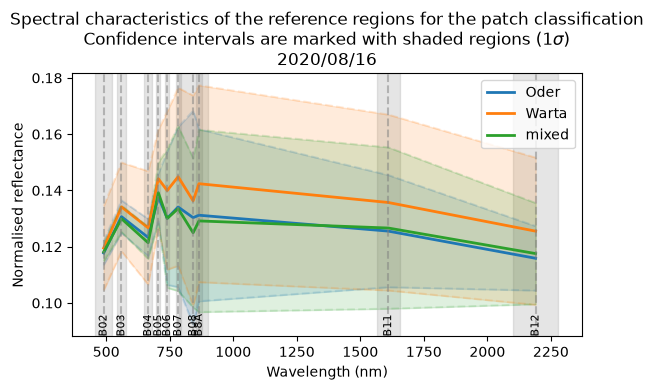

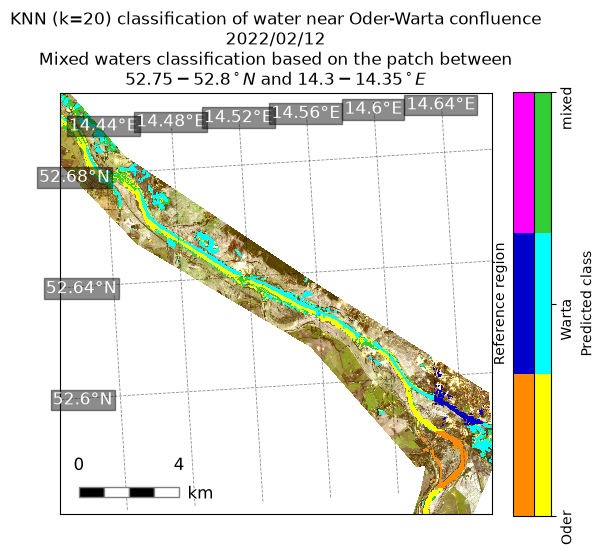

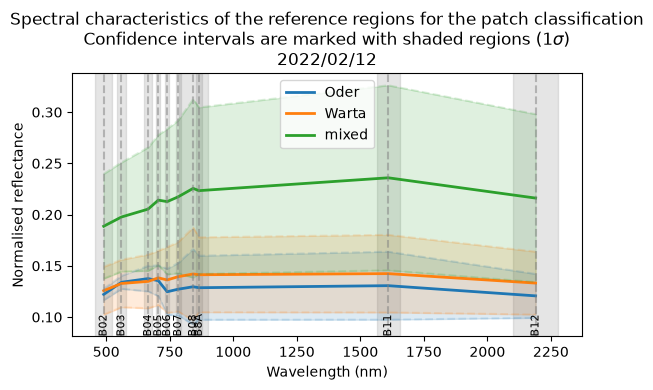

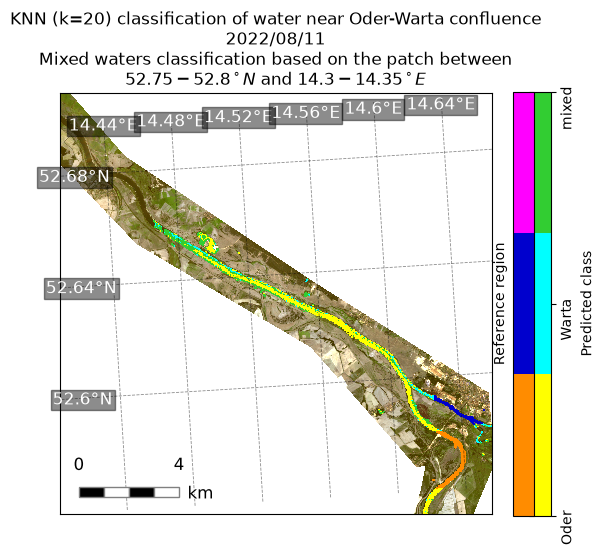

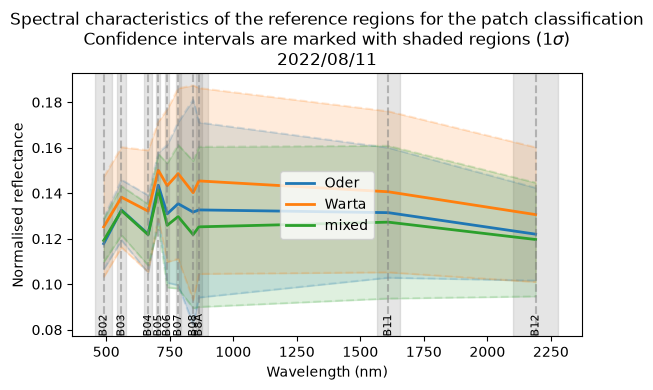

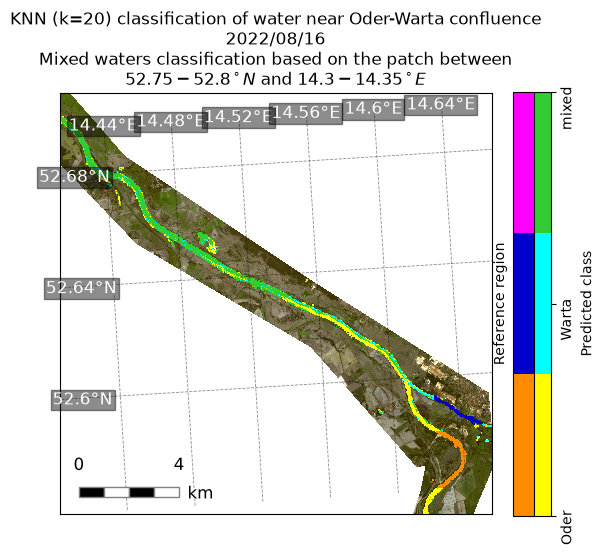

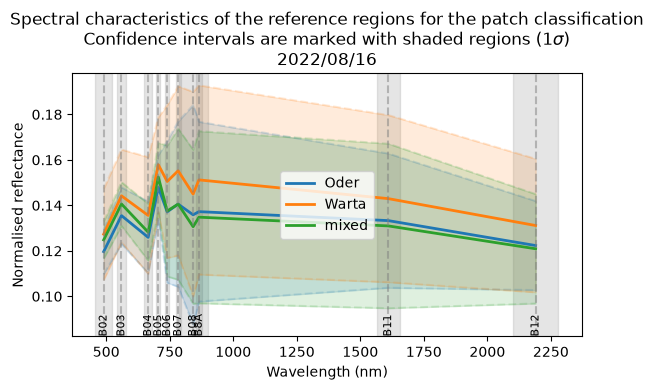

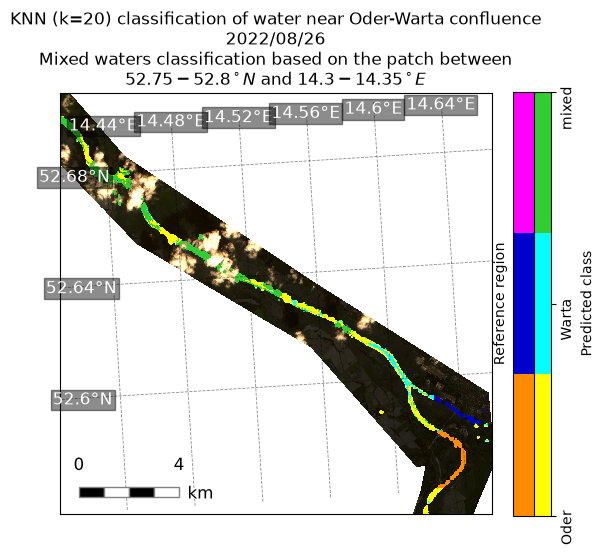

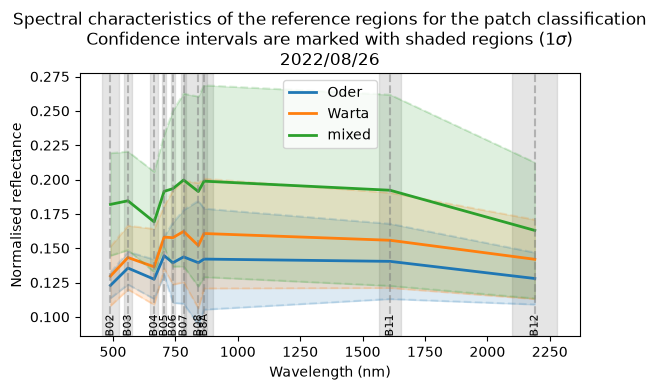

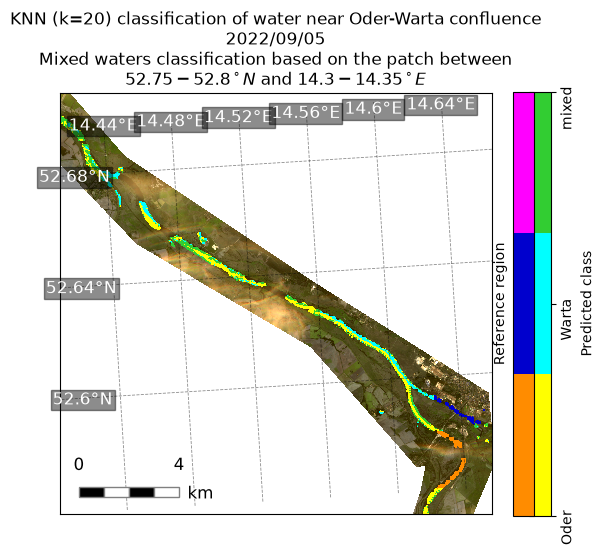

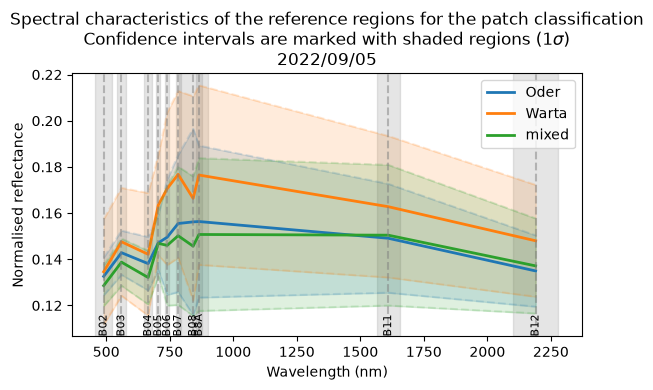

In [5]:
for date in sorted(date_tiles.keys()):
    year, month, day = date[:4], date[4:6], date[6:8]
    df = None
    crs = None
    for aoi in aois:
        if not aoi in date_tiles[date]:
            continue
        tile = date_tiles[date][aoi]
        local_df, target_crs = stacks_to_dataframe(
            bands_10m={"B02": 1, "B03": 2, "B04": 3, "B08": 4},
            bands_20m={"B05": 1, "B06": 2, "B07": 3, "B8A": 4, "B11": 5, "B12": 6, "SCL": 7},
            stack_20m_path=tile / "20m_Stack.tif",
            stack_10m_path=tile / "10m_Stack.tif",
        )
        if crs is None:
            crs = target_crs
        if df is None:
            df = local_df
        else:
            df = pd.concat([df, local_df], ignore_index=True)
    if df is None:
        continue
    plot_df = df.copy()
    rgb = plot_df[["B02", "B03", "B04"]].to_numpy(copy=True)

    water_mask = plot_df["SCL"].eq(6).fillna(False).to_numpy()
    oder_mask = mask_in_box(plot_df, crs, oder_lims)&water_mask
    warta_mask = mask_in_box(plot_df, crs, warta_lims)&water_mask
    mixed_mask = mask_in_box(plot_df, crs, mixed_lims)&water_mask
    if not (oder_mask.any() and warta_mask.any() and mixed_mask.any()):
        continue
    labeled_masks = {
        "Oder": oder_mask,
        "Warta": warta_mask,
        "mixed": mixed_mask
    }
    class_df, model = classify(plot_df, labeled_masks, water_mask, k=k_neighbours)
    ndwi = (plot_df["B08"] - plot_df["B11"]) / (plot_df["B08"] + plot_df["B11"])
    ndwi[~water_mask] = np.nan
    ndwi_min, ndwi_max = -1, 1
    ndwi[ndwi < ndwi_min] = -1
    ndwi[ndwi > ndwi_max] = ndwi_max

    rgb[:,0] *= 1.2
    rgb[:,2] *= 0.75
    rgb[rgb > 1.0] = 1.0
    rgb[rgb < 0.0] = 0.0

    fig, ax = plt.subplots(figsize=(6,8))
    add_grid_lines(crs, (west, south, east, north), ax, 0.04, linecolour="black")
    ax.scatter(
        plot_df["x"],
        plot_df["y"],
        c=normalise_rgb(rgb),
        s=1,
        marker="s",
        linewidths=0,
    )

    label_to_code = {label: code for code, label in enumerate(labeled_masks.keys())}

    cmap = ListedColormap(["yellow", "cyan", "limegreen"])
    ref_cmap = ListedColormap(["darkorange", "mediumblue", "magenta"])

    class_codes = class_df["predicted_class"].map(label_to_code)
    ref_df = class_df.copy()
    all_labeled_mask = np.logical_or.reduce(
        [np.asarray(mask, dtype=bool) for mask in labeled_masks.values()]
    )[water_mask]
    ref_df[~all_labeled_mask] = np.nan

    class_sc = ax.scatter(
        class_df["x"],
        class_df["y"],
        c=class_codes,
        cmap=cmap,
        s=1,
        marker="s",
        linewidths=0,
    )

    ref_sc = ax.scatter(
        ref_df["x"],
        ref_df["y"],
        c=class_codes,
        cmap=ref_cmap,
        s=1,
        marker="s",
        linewidths=0,
    )

    cbar = plt.colorbar(class_sc, ax=ax, ticks=np.arange(len(labeled_masks)), pad=-0.115, shrink=0.55)
    ref_cbar = plt.colorbar(ref_sc, ax=ax, pad=0.04, shrink=0.55)
    cbar.ax.set_yticklabels(labeled_masks.keys())
    cbar.ax.tick_params(axis="y", labelrotation=90)
    ref_cbar.set_ticks([])
    ref_cbar.ax.tick_params(left=False, right=False)
    cbar.set_label("Predicted class")
    ref_cbar.set_label("Reference region")
    ref_cbar.ax.yaxis.set_label_position("left")

    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"KNN (k={k_neighbours}) classification of water near Oder-Warta confluence\n{year}/{month}/{day}\n" +
                 f"Mixed waters classification based on the patch between\n${mixed_lims[2]}-{mixed_lims[0]}^\\circ N$ and ${mixed_lims[3]}-{mixed_lims[1]}^\\circ E$")
    scale_bar(
        ax=ax,
        location="lower left",
        style="boxes",
        bar={"projection":target_crs[-4:],"minor_type":"none","edgecolors": "grey"},
        text={"color": "white"},
        labels={"style":"first_last"}
    )

    plt.tight_layout()
    if SAVE_FIGS:
        FIG_DIR = Path(f"figures/classification/maps/Kostrzyn/{year}-{month}-{day}.jpg")
        FIG_DIR.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR, dpi=120, pad_inches=0.1, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(6, 4))
    for label in labeled_masks:
        mask_df = plot_df[labeled_masks[label]]
        means = []
        stds = []
        for band in band_names:
            band_values = mask_df[band].values
            means.append(np.nanmean(band_values))
            stds.append(np.nanstd(band_values))
        means = np.array(means)
        stds = np.array(stds)
        lower = means - stds
        upper = means + stds
        line, = ax.plot(wavelengths, means, label=label, linewidth=2)
        color = line.get_color()
        ax.fill_between(wavelengths, lower, upper, color=color, alpha=0.15)
        ax.plot(wavelengths, lower, color=color, alpha=0.15, linestyle='--')
        ax.plot(wavelengths, upper, color=color, alpha=0.15, linestyle='--')
    plt.legend()
    plot_spectra_labels(wavelengths, bandwidths, band_names, ax, fontsize=8)
    ax.set_title("Spectral characteristics of the reference regions for the patch classification\n" +
                 "Confidence intervals are marked with shaded regions ($1\\sigma$)\n" +
                 f"{year}/{month}/{day}")
    plt.tight_layout()
    if SAVE_FIGS:
        FIG_DIR = Path(f"figures/classification/spectral/Kostrzyn/{year}-{month}-{day}.jpg")
        FIG_DIR.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR, dpi=120, pad_inches=0.1, bbox_inches="tight")
    plt.show()
